# Week 3: Laya ticket-routing specialization

Run all cells in order. The default is an offline workflow check. Mock results are simulated and do not measure training. See [the workflow guide](../README.md) for real training commands and interpretation.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys
import tempfile
from IPython.display import Markdown, display
from system_one_models.finetuning import verify_dataset, scenarios, fit_temperature
from system_one_models.decision_benchmark import create_backend, run_benchmark

MOCK = True
# Locate the week folder from either the root or notebook working directory.
WEEK = next(p / "week_03" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "week_03" / "prepare_data.py").is_file())
WORK = Path(tempfile.mkdtemp(prefix="system-one-week03-"))
DATA = WORK / "data" if MOCK else WEEK / "data" / "tickets-v1"
RUN = WORK / "run" if MOCK else WEEK / "runs" / "ticket-head-v1"
REPORTS = WORK / "reports"
print("Mode:", "MOCK — simulated answers" if MOCK else "REAL — weights, GPU, optional hosted calls")
print("Artifacts:", WORK)

def script(name, *arguments):
    subprocess.run([sys.executable, str(WEEK / name), *map(str, arguments)], check=True)


Mode: REAL — weights, GPU, optional hosted calls
Artifacts: /tmp/system-one-week03-s3kkn_n0


## Dataset and teacher review

Generate 3,000 balanced requests. Validation families and calibration families are separate. Manually review the training spot-check file before a real run. Never use the frozen test to choose training settings.

In [2]:
if not DATA.exists():
    script("prepare_data.py", "--output", DATA, "--count", 3000)
splits = verify_dataset(DATA)
print({name: len(rows) for name, rows in splits.items()})
spot_checks = [json.loads(line) for line in (DATA / "spot-check.jsonl").read_text().splitlines()]
for example in spot_checks[:5]:
    print(example["state"], "=>", example["label"])


{'train': 2400, 'validation': 150, 'calibration': 150, 'test': 300}
We have not used your service yet. Can we discuss buying access for 93631 people? Request reference: cdd0b4d4554227de. => sales
How do I rename project 94545 in the settings menu? Request reference: c90b945450d3802d. => support
I want to purchase 94788 subscriptions. Is there a volume discount? Request reference: c2fa1da878308631. => sales
My invoice 33508 has an incorrect tax amount. Can you correct the charge? Request reference: f41ea3ac5fd23109. => billing
A charge appeared after my free trial ended, account 41567. I want it refunded. Request reference: 42c18a62ef48e8d5. => billing


## Train, then fit temperature

Head-only CE is the first experiment. Real mode starts training only in an empty run folder. To try full tuning or RLCD, use the commands in the README after reviewing validation. Calibration uses its own split. The mock branch demonstrates scalar fitting with invented logits; it creates no checkpoint.

In [3]:
if MOCK:
    import numpy as np
    fake_logits = np.array([[8., 0., 0.]] * 10)
    fake_labels = np.array([0] * 6 + [1] * 2 + [2] * 2)
    print("Demonstration temperature (invented logits):", fit_temperature(fake_logits, fake_labels))
else:
    if not (RUN / "best" / "rl_agent_config.json").exists():
        script("train.py", "--data", DATA, "--output", RUN)
    display(json.loads((RUN / "history.json").read_text()))
    if not (RUN / "calibrated" / "rl_agent_config.json").exists():
        script("calibrate.py", "--model", RUN / "best", "--data", DATA, "--output", RUN / "calibrated")


[{'epoch': 1,
  'training_loss': 0.2725121338726846,
  'accuracy': 1.0,
  'ece': 0.032621996005376214,
  'nll': 0.04052346363185885},
 {'epoch': 2,
  'training_loss': 0.10434288711541835,
  'accuracy': 1.0,
  'ece': 0.0006001766522725216,
  'nll': 0.0006034700948240849},
 {'epoch': 3,
  'training_loss': 0.03832275666092356,
  'accuracy': 1.0,
  'ece': 8.273124694868628e-06,
  'nll': 8.27331311337313e-06}]

## Frozen-test comparison and legacy slice

Both test and legacy reports use the existing scoring harness. Mock model names use the same simulated distribution and do not imply different quality. Real checkpoints run sequentially to conserve GPU memory. Hosted evaluation is an optional CLI step requiring credentials.

In [4]:
arguments = ["--data", DATA, "--output", REPORTS]
if not MOCK:
    arguments += ["--real", "--checkpoint", f"laya-head={RUN / 'best'}",
                  "--checkpoint", f"laya-calibrated={RUN / 'calibrated'}"]
script("evaluate.py", *arguments)
display(Markdown((REPORTS / "comparison.md").read_text()))


Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 1747.92it/s]
/home/scott/github/system-one-models/.venv/lib/python3.13/site-packages/laya/agent.py:2110: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


# Week 3 ticket-routing comparison

**Real inference on the specified checkpoints.**

## Frozen synthetic test

# Bake-off results

| backend | items | choice acc | noul acc | score MAE | score rho | ECE | Brier | p50 ms | est $/1k |
|---|---|---|---|---|---|---|---|---|---|
| laya-base | 300 | 0.833 | -- | -- | -- | 0.231 | 0.134 | 20.6 | -- |
| laya-head | 300 | 0.833 | -- | -- | -- | 0.076 | 0.039 | 20.9 | -- |
| laya-calibrated | 300 | 0.833 | -- | -- | -- | 0.074 | 0.036 | 20.0 | -- |

_choice acc / noul acc_: fraction of exact-label matches. _score MAE_: mean |expected score - true level| (lower is better). _score rho_: Spearman rank correlation of predicted vs true levels. _ECE_: expected calibration error over probability bins (lower is better; values depend on the dataset). _Brier_: mean squared error of top-label probabilities versus correctness (lower is better). _est $/1k_: estimated USD per 1,000 scenario requests, using supplied input-token pricing._

## laya-base — reliability diagram
_300 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 68 | 0.462 | 0.353 |
| 0.5-0.6 | 46 | 0.538 | 0.870 |
| 0.6-0.7 | 83 | 0.644 | 1.000 |
| 0.7-0.8 | 51 | 0.756 | 1.000 |
| 0.8-0.9 | 2 | 0.817 | 1.000 |
| 0.9-1.0 | 50 | 0.915 | 1.000 |

## laya-head — reliability diagram
_300 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 38 | 0.435 | 0.000 |
| 0.5-0.6 | 10 | 0.544 | 0.100 |
| 0.6-0.7 | 3 | 0.638 | 0.333 |
| 0.7-0.8 | 2 | 0.784 | 0.500 |
| 0.8-0.9 | 0 | -- | -- |
| 0.9-1.0 | 247 | 0.998 | 1.000 |

## laya-calibrated — reliability diagram
_300 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 42 | 0.426 | 0.000 |
| 0.5-0.6 | 7 | 0.545 | 0.143 |
| 0.6-0.7 | 2 | 0.622 | 0.500 |
| 0.7-0.8 | 2 | 0.749 | 0.500 |
| 0.8-0.9 | 1 | 0.868 | 1.000 |
| 0.9-1.0 | 246 | 0.998 | 1.000 |


## Existing bakeoff ticket-routing slice

# Bake-off results

| backend | items | choice acc | noul acc | score MAE | score rho | ECE | Brier | p50 ms | est $/1k |
|---|---|---|---|---|---|---|---|---|---|
| laya-base | 4 | 1.000 | -- | -- | -- | 0.207 | 0.086 | 32.6 | -- |
| laya-head | 4 | 1.000 | -- | -- | -- | 0.002 | 0.000 | 21.2 | -- |
| laya-calibrated | 4 | 1.000 | -- | -- | -- | 0.005 | 0.000 | 20.2 | -- |

_choice acc / noul acc_: fraction of exact-label matches. _score MAE_: mean |expected score - true level| (lower is better). _score rho_: Spearman rank correlation of predicted vs true levels. _ECE_: expected calibration error over probability bins (lower is better; values depend on the dataset). _Brier_: mean squared error of top-label probabilities versus correctness (lower is better). _est $/1k_: estimated USD per 1,000 scenario requests, using supplied input-token pricing._

## laya-base — reliability diagram
_4 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 1 | 0.447 | 1.000 |
| 0.5-0.6 | 0 | -- | -- |
| 0.6-0.7 | 0 | -- | -- |
| 0.7-0.8 | 0 | -- | -- |
| 0.8-0.9 | 1 | 0.814 | 1.000 |
| 0.9-1.0 | 2 | 0.956 | 1.000 |

## laya-head — reliability diagram
_4 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 0 | -- | -- |
| 0.5-0.6 | 0 | -- | -- |
| 0.6-0.7 | 0 | -- | -- |
| 0.7-0.8 | 0 | -- | -- |
| 0.8-0.9 | 0 | -- | -- |
| 0.9-1.0 | 4 | 0.998 | 1.000 |

## laya-calibrated — reliability diagram
_4 scored items, 0 errors_

| prob bin | n | avg conf | emp acc |
|---|---|---|---|
| 0.0-0.5 | 0 | -- | -- |
| 0.5-0.6 | 0 | -- | -- |
| 0.6-0.7 | 0 | -- | -- |
| 0.7-0.8 | 0 | -- | -- |
| 0.8-0.9 | 0 | -- | -- |
| 0.9-1.0 | 4 | 0.995 | 1.000 |


## Interpretation

Accuracy measures correctly routed tickets. Errors mean a customer may reach the wrong team. ECE compares stated confidence with observed correctness; Brier is the squared error of predicted-class confidence against correctness, not multiclass Brier. Use calibration bins in each report as a reliability diagram. A fitted temperature changes confidence, not the top choice. p50/p95 describe typical and slower requests. Inspect errors before interpreting accuracy. Prices remain unknown without input pricing.

The synthetic teacher labels single-intent templates, not real customer tickets. Held-out template families reduce leakage but do not establish real-world quality. The four-question bakeoff slice is small and labels are subjective. Hosted calls include network time; local calls do not. Initialization and warmup are excluded. Local hardware and output-token costs are excluded. Local execution does not guarantee privacy. No tuning improvement or production readiness is assumed.

Before deciding to deploy, compare accuracy and errors on the same frozen test, then use confidence bins to choose which tickets need human review. Evaluate on manually labeled real tickets before making an operating-cost or quality decision.


## Reliability diagram

Compare predicted-class probability with observed correctness. Each point is a probability bin. Sparse bins are unstable. Accuracy improvements and confidence improvements answer different product questions.

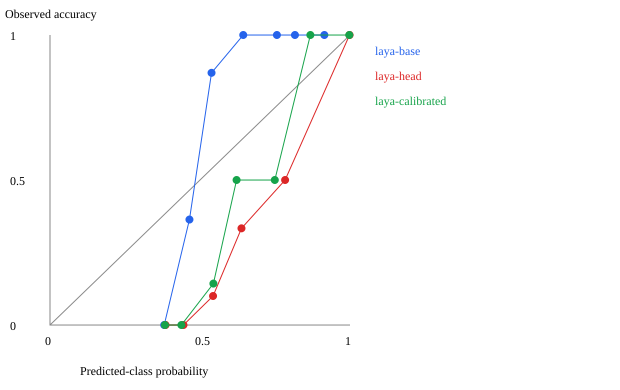

In [5]:
from IPython.display import SVG
display(SVG(filename=str(REPORTS / "test" / "reliability.svg")))


## Review and next experiment

Record accuracy, answer errors, confidence reliability, and p50/p95 latency from the frozen test. Review validation before deciding on full training. In real mode, identify customer mistakes that a human review threshold should catch; the synthetic test is insufficient for deployment.

The stretch command in the README collects fresh mistakes only from training families and preserves every held-out split. Recalibrate each newly trained model. No improvement is established by this offline notebook.